# 🚀 Thực Hành Buổi 32: Transfer Learning (MobileNetV2) & Data Augmentation trên CIFAR-10
**Học viên:** Bùi Văn Thắng — Lớp AI Engineer K10  
**Mục tiêu thực chiến:**
1. **Data Augmentation (Làm giàu ảnh):** Tự động lật ngang (`RandomFlip`), xoay nghiêng (`RandomRotation`), phóng to/thu nhỏ (`RandomZoom`) để chống học vẹt (`Overfitting`).
2. **Transfer Learning (Học chuyển giao):** Mượn "cặp mắt" siêu mô hình **`MobileNetV2`** của Google (đã học 1,4 triệu ảnh `ImageNet`), đóng băng trọng số gốc (`base_model.trainable = False` — *Feature Extraction*) và gắn phần đầu phân loại 10 lớp `CIFAR-10`.
3. **So sánh hiệu năng:** Đối chiếu trực tiếp độ chính xác và số tham số huấn luyện so với mạng CNN tự xây từ đầu.

### 📌 Bước 1 (Cell 1): Khai báo thư viện (Imports)

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow version :", tf.__version__)

TensorFlow version : 2.22.0-rc0


### 📌 Bước 2 (Cell 2): Tải dữ liệu CIFAR-10 & Chuẩn bị tập huấn luyện nhanh

In [18]:
(X_train_full, y_train_full), (X_test_full, y_test_full) = cifar10.load_data()

class_names = ['May bay', 'O to', 'Chim', 'Meo', 'Huou', 'Cho', 'Ech', 'Ngua', 'Tau thuy', 'Xe tai']

X_train = X_train_full[:4000].astype("float32")
y_train = y_train_full[:4000]
X_test = X_test_full[:1000].astype("float32")
y_test = y_test_full[:1000]

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)

Train shape: (4000, 32, 32, 3) | Test shape: (1000, 32, 32, 3)


### 📌 Bước 3 (Cell 3): Xây dựng bộ Data Augmentation & Xem thử ảnh biến đổi

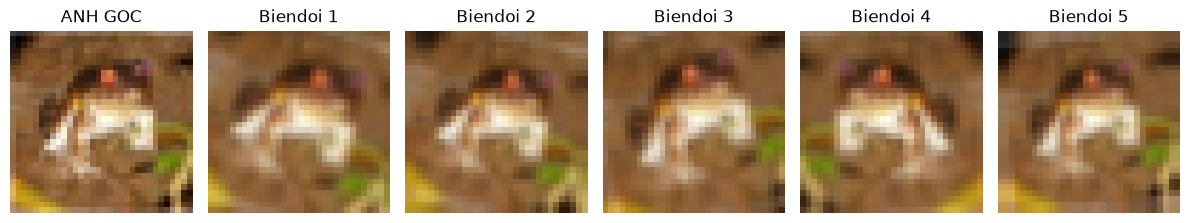

In [19]:
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
], name="dat_augmentation")

sample_img = X_train[0:1]
plt.figure(figsize=(12, 3))
plt.subplot(1, 6, 1)
plt.imshow(sample_img[0].astype("uint8"))
plt.title("ANH GOC")
plt.axis("off")

for i in range(5):
    aug_img = data_augmentation(sample_img, training=True)
    plt.subplot(1, 6, i + 2)
    plt.imshow(aug_img[0].numpy().astype("uint8"))
    plt.title(f"Biendoi {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### 📌 Bước 4 (Cell 4): Xây dựng mô hình Transfer Learning với MobileNetV2 (Feature Extraction)

In [20]:
base_model = MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = layers.Input(shape=(32, 32, 3), name="input_cifar10")
x = data_augmentation(inputs)
x = layers.Resizing(96, 96, name="resize_96x96")(x)
x = preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D(name="gap")(x)
x = layers.Dropout(0.3, name="dropout")(x)
outputs = layers.Dense(10, activation="softmax", name="otput_10_classes")(x)

model = models.Model(inputs=inputs, outputs=outputs, name="MobileNetV2_Transfer_CIFAR10")
model.summary()

Model: "MobileNetV2_Transfer_CIFAR10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_cifar10 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dat_augmentation (Sequential)   │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resize_96x96 (Resizing)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_2 (TrueDivide)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_2 (Subtract)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ otput_10_classes (Dense)        │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 📌 Bước 5 (Cell 5): Biên dịch (Compile) & Huấn luyện mô hình

In [21]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=6,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop]
)

Epoch 1/6
50/50 ━━━━━━━━━━━━━━━━━━━━ 6s 82ms/step - accuracy: 0.3578 - loss: 1.8994 - val_accuracy: 0.6187 - val_loss: 1.1741
Epoch 2/6
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - accuracy: 0.5913 - loss: 1.1819 - val_accuracy: 0.7113 - val_loss: 0.8991
Epoch 3/6
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 68ms/step - accuracy: 0.6503 - loss: 1.0206 - val_accuracy: 0.7387 - val_loss: 0.8215
Epoch 4/6
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 67ms/step - accuracy: 0.6719 - loss: 0.9390 - val_accuracy: 0.7600 - val_loss: 0.7584
Epoch 5/6
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 68ms/step - accuracy: 0.6909 - loss: 0.8925 - val_accuracy: 0.7613 - val_loss: 0.7490
Epoch 6/6
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 72ms/step - accuracy: 0.7038 - loss: 0.8511 - val_accuracy: 0.7625 - val_loss: 0.7290


### 📌 Bước 6 (Cell 6): Đánh giá trên tập Test & Vẽ biểu đồ Learning Curves

Do chinh xac tren tap Test(1.000 anh): 76.50%


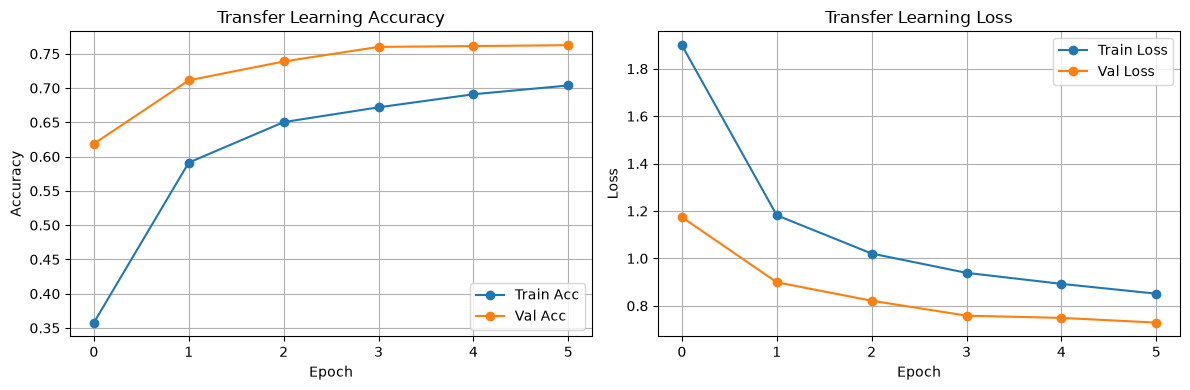

In [22]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Do chinh xac tren tap Test(1.000 anh): {test_acc * 100:.2f}%")

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], marker="o", label="Train Acc")
plt.plot(history.history["val_accuracy"], marker="o", label= "Val Acc")
plt.title("Transfer Learning Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], marker="o", label="Train Loss")
plt.plot(history.history["val_loss"], marker="o", label="Val Loss")
plt.title("Transfer Learning Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### 📌 Bước 7 (Cell 7): Kiểm tra dự đoán thực tế & So sánh với Mini-ResNet tự xây

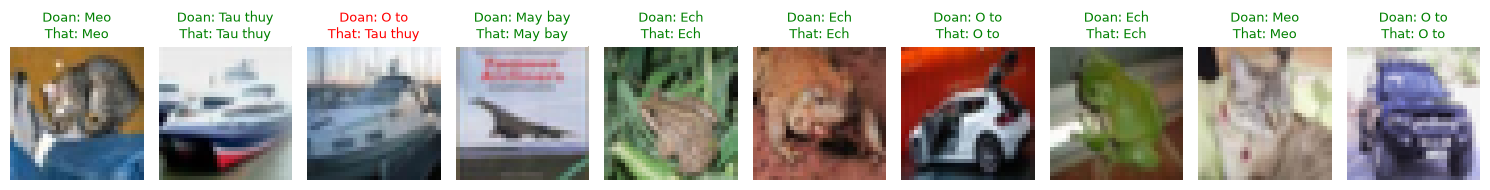

In [26]:
y_pred = model.predict(X_test[:10], verbose=0)
y_pred_classed = np.argmax(y_pred, axis=1)

plt.figure(figsize=(15, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_test[i].astype("uint8"))
    true_label = class_names[int(y_test[i][0])]
    pred_label = class_names[int(y_pred_classed[i])]
    color = "green" if true_label == pred_label else "red"
    plt.title(f"Doan: {pred_label}\nThat: {true_label}", color=color, fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()